# Looply | 군집 분석 (scikit-learn)

웹앱의 "군집 분석" 화면은 브라우저의 JavaScript로 KMeans를 구현했습니다. 이 노트북은 **같은 데이터와 같은 전처리**를 Python(scikit-learn)으로 다시 돌려서 다음을 확인합니다.

1. 군집 수(k) 2~6개를 실루엣 점수 등으로 비교하고, 보고용 군집 수를 정한다.
2. 선택한 k=3의 군집 특징을 해석한다.
3. 웹앱(JavaScript) 결과가 scikit-learn 결과와 얼마나 같은지 비교한다.

**분석 대상:** 환경성적표지 평가계수 중 `원료 및 에너지 생산` · 기준 단위 `kg` 항목 가운데, 5개 영향범주(탄소·자원·산성화·부영양화·물발자국)의 값이 모두 있고 0보다 큰 항목.

> 군집은 비슷한 계수를 가진 항목을 묶은 **탐색용 분류**이며 환경성능 순위나 공식 분류가 아닙니다.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

# 한글 글꼴 (환경에 있는 것을 자동으로 사용)
plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False

DATA = Path("../data/lca_factors_clean.csv")
if not DATA.exists():            # 저장소 루트에서 실행한 경우
    DATA = Path("data/lca_factors_clean.csv")
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 1. 데이터 불러오기와 표본 선택

`해당없음`은 0이 아니라 **값이 없다**는 뜻이므로 결측(NaN)으로 바꿉니다. 로그를 쓰려면 양수만 가능해서 0 이하도 제외합니다.

In [2]:
df = pd.read_csv(DATA, encoding="utf-8-sig").replace("해당없음", np.nan)
IMP = ["탄소발자국(kg CO2 eq)", "자원발자국(kg Sb eq)", "산성비(kg SO2 eq)",
       "부영양화(kg PO43- eq)", "물소모계수(m3 H2O eq)"]
df[IMP] = df[IMP].apply(pd.to_numeric, errors="coerce")

stage = df[df["대분류"] == "원료 및 에너지 생산"]
kg = stage[stage["단위"].str.strip() == "kg"]
d = kg.dropna(subset=IMP)
d = d[(d[IMP] > 0).all(axis=1)].copy()

print("전체 항목:", len(df))
print("원료 및 에너지 생산:", len(stage))
print("  그중 기준 단위 kg:", len(kg))
print("  그중 5개 영향범주 모두 양수:", len(d), "  <- 분석 표본")
print()
print("kg 항목의 영향범주별 빈 값 비율")
print(kg[IMP].isna().mean().round(2).to_string())

전체 항목: 398
원료 및 에너지 생산: 198
  그중 기준 단위 kg: 189
  그중 5개 영향범주 모두 양수: 142   <- 분석 표본

kg 항목의 영향범주별 빈 값 비율
탄소발자국(kg CO2 eq)     0.00
자원발자국(kg Sb eq)      0.04
산성비(kg SO2 eq)       0.08
부영양화(kg PO43- eq)    0.16
물소모계수(m3 H2O eq)     0.13


## 2. 로그 변환과 표준화

계수가 0.0001부터 수십까지 수백만 배 차이가 나서, 그대로 쓰면 큰 값 몇 개가 거리 계산을 좌우합니다. **log10**으로 크기 차이를 줄이고, 영향범주마다 단위가 달라 **표준화**(평균 0, 표준편차 1)합니다. (웹앱과 같은 방식)

In [3]:
X = StandardScaler().fit_transform(np.log10(d[IMP].to_numpy()))
print("표준화 후 평균(거의 0):", X.mean(axis=0).round(6))
print("표준화 후 표준편차(1):", X.std(axis=0).round(6))

표준화 후 평균(거의 0): [-0.  0. -0. -0. -0.]
표준화 후 표준편차(1): [1. 1. 1. 1. 1.]


## 3. 군집 수(k) 비교

- **실루엣 점수**: 높을수록 군집이 뚜렷함 (최대 1)
- **Davies-Bouldin**: 낮을수록 군집이 잘 분리됨
- **관성(inertia)**: 군집 안 거리 합. k가 커지면 항상 줄어들어서 꺾이는 지점만 참고
- **시드 안정성**: 시작 위치(random_state)를 10가지로 바꿔 돌렸을 때 결과가 같은 정도 (1.00이면 완전히 같음, ARI)

In [4]:
rows = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    others = [KMeans(n_clusters=k, n_init=10, random_state=s).fit_predict(X) for s in range(1, 10)]
    stability = np.mean([adjusted_rand_score(km.labels_, o) for o in others])
    rows.append({
        "k": k,
        "실루엣": round(silhouette_score(X, km.labels_), 3),
        "Davies-Bouldin": round(davies_bouldin_score(X, km.labels_), 2),
        "관성": round(km.inertia_),
        "시드 안정성": round(stability, 2),
        "군집 크기": sorted(np.bincount(km.labels_).tolist(), reverse=True),
    })
score = pd.DataFrame(rows).set_index("k")
print(score.to_string())

     실루엣  Davies-Bouldin   관성  시드 안정성                   군집 크기
k                                                            
2  0.329            1.19  451    1.00                [86, 56]
3  0.327            1.15  348    1.00            [85, 40, 17]
4  0.300            1.13  292    0.91        [64, 37, 24, 17]
5  0.307            1.09  245    0.96     [54, 36, 24, 23, 5]
6  0.318            0.93  220    0.94  [55, 36, 23, 23, 3, 2]


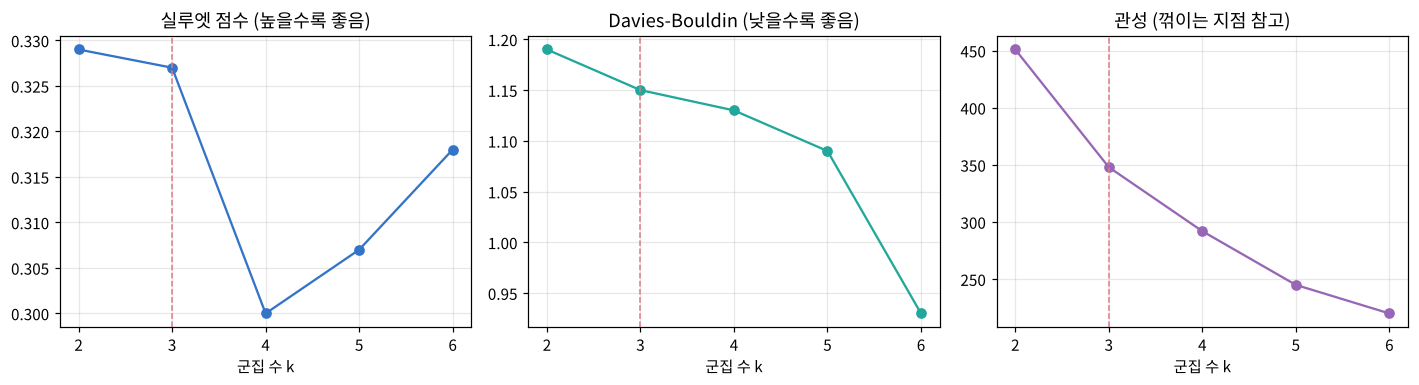

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].plot(score.index, score["실루엣"], "o-", color="#3474c8"); ax[0].set_title("실루엣 점수 (높을수록 좋음)")
ax[1].plot(score.index, score["Davies-Bouldin"], "o-", color="#22a89b"); ax[1].set_title("Davies-Bouldin (낮을수록 좋음)")
ax[2].plot(score.index, score["관성"], "o-", color="#9866b6"); ax[2].set_title("관성 (꺾이는 지점 참고)")
for a in ax:
    a.set_xlabel("군집 수 k"); a.set_xticks(score.index); a.grid(alpha=.3)
    a.axvline(3, color="#de7b86", ls="--", lw=1)
plt.tight_layout(); plt.show()

### 보고용 군집 수: **k = 3**

| 확인 항목 | 결과 |
|---|---|
| 실루엣 점수 | k=2: 0.329, **k=3: 0.327**, k=4: 0.300, k=5: 0.307, k=6: 0.318 → 모두 0.30~0.33으로 **차이가 작음** |
| 시드 안정성 | k=2, **k=3은 1.00**(시작 위치를 바꿔도 항상 같은 결과), k=4는 0.91로 떨어짐 |
| 군집 크기 | k=5, 6은 안정성이 0.94~0.96이지만 2~5개짜리 아주 작은 군집이 생겨 해석이 어려움 |
| 해석 | 3개는 "낮음 / 보통 / 높음"으로 설명하기 쉬움 |

실루엣 점수만 보면 k=2가 가장 높지만 k=3과의 차이는 0.002입니다. 점수가 사실상 같다면 **결과가 안정적이고, 2개보다 한 단계 더 구분되며, 설명하기 쉬운 3개**를 보고용으로 선택했습니다.

**주의:** 점수가 0.33 정도라 군집 경계가 뚜렷한 편은 아닙니다. 군집은 데이터를 훑어보는 용도로만 해석합니다.

## 4. k=3 군집 해석

군집 번호는 중심값의 평균이 낮은 순서로 붙였습니다. 번호는 순위가 아니라 구분용입니다. (웹앱과 같은 규칙)

In [6]:
km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(X)
order = np.argsort(km.cluster_centers_.mean(axis=1))
rank = {old: new + 1 for new, old in enumerate(order)}
d["군집"] = [rank[l] for l in km.labels_]
centers = pd.DataFrame(km.cluster_centers_[order], columns=["탄소", "자원", "산성화", "부영양화", "물발자국"],
                       index=[1, 2, 3])
centers.index.name = "군집"

print("군집별 항목 수")
print(d["군집"].value_counts().sort_index().to_string())
print()
print("군집 중심값 (표준화 점수: +면 전체 평균보다 높은 편, -면 낮은 편)")
print(centers.round(2).to_string())
print()
d["거리"] = np.linalg.norm(X - km.cluster_centers_[km.labels_], axis=1)
for g in [1, 2, 3]:
    names = d[d["군집"] == g].nsmallest(3, "거리")
    print(f"{g}번 군집 대표 항목:", ", ".join(names["원료_에너지"] + "(" + names["구분"] + ")"))

out = d[["구분", "원료_에너지", "군집"]].copy()
out.index.name = "행번호"
out.to_csv("../data/sklearn_kmeans_k3.csv", encoding="utf-8-sig")

군집별 항목 수
군집
1    40
2    85
3    17

군집 중심값 (표준화 점수: +면 전체 평균보다 높은 편, -면 낮은 편)
      탄소    자원   산성화  부영양화  물발자국
군집                              
1  -1.07 -1.10 -0.88 -0.89 -0.47
2   0.23  0.26  0.03  0.05  0.21
3   1.38  1.31  1.93  1.83  0.06

1번 군집 대표 항목: 납(금속), 염소(기초화학물질), 건식 단미사료(재활용 원료)(기타)
2번 군집 대표 항목: 에틸렌옥사이드(기초화학물질), 스티렌 아크릴로니트릴(기초화학물질), 트리에틸렌글리콜(TEG)(기초화학물질)
3번 군집 대표 항목: 에피클로로히드린(기초화학물질), 카프로락탐(기초화학물질), 부탄(기초화학물질)


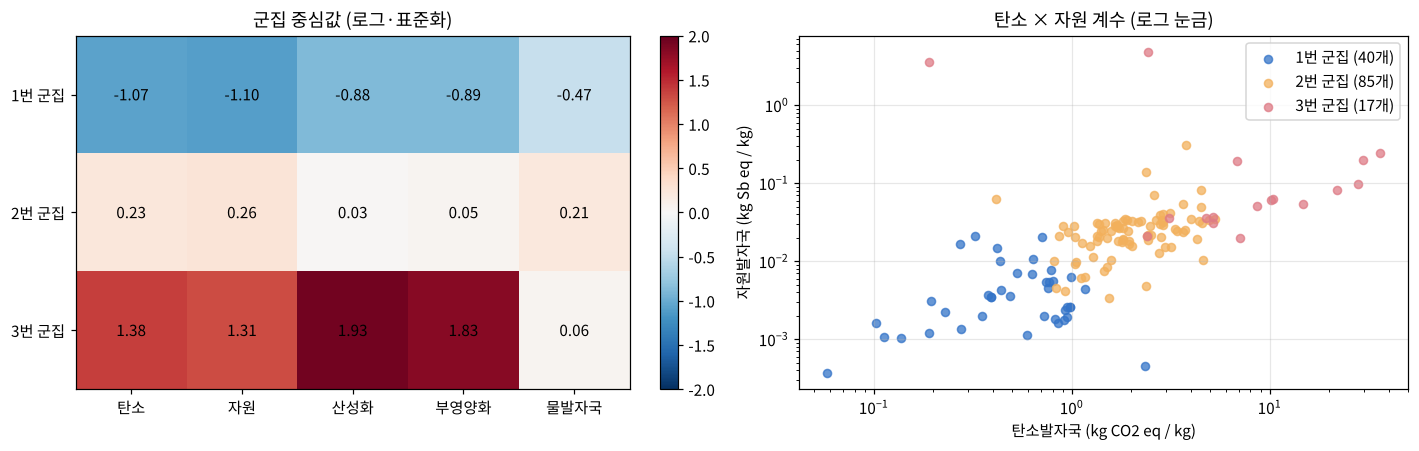

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
im = ax[0].imshow(centers.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
ax[0].set_xticks(range(5)); ax[0].set_xticklabels(centers.columns)
ax[0].set_yticks(range(3)); ax[0].set_yticklabels([f"{i}번 군집" for i in centers.index])
for i in range(3):
    for j in range(5):
        ax[0].text(j, i, f"{centers.values[i, j]:.2f}", ha="center", va="center")
ax[0].set_title("군집 중심값 (로그·표준화)"); plt.colorbar(im, ax=ax[0], fraction=.04)

colors = {1: "#3474c8", 2: "#f2b05c", 3: "#de7b86"}
for g, sub in d.groupby("군집"):
    ax[1].scatter(sub[IMP[0]], sub[IMP[1]], s=28, alpha=.75, color=colors[g], label=f"{g}번 군집 ({len(sub)}개)")
ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("탄소발자국 (kg CO2 eq / kg)"); ax[1].set_ylabel("자원발자국 (kg Sb eq / kg)")
ax[1].set_title("탄소 × 자원 계수 (로그 눈금)"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 5. 웹앱(JavaScript) 결과와 비교

`data/web_kmeans_k3.csv`는 웹앱에 들어 있는 JavaScript KMeans(k-means++ 초기화, 10회 시도)로 같은 표본을 k=3으로 묶은 결과입니다. 두 결과가 얼마나 같은지 **ARI**(1.0이면 완전히 같음)로 확인합니다.

In [8]:
web = pd.read_csv("../data/web_kmeans_k3.csv", encoding="utf-8-sig").set_index("행번호")["웹군집"]
both = d["군집"].to_frame("scikit-learn").join(web.rename("웹(JS)"))
print("비교 항목 수:", len(both), "(웹에 없는 항목:", int(both["웹(JS)"].isna().sum()), ")")
print("ARI:", round(adjusted_rand_score(both["scikit-learn"], both["웹(JS)"]), 3))
print("같은 군집으로 배정된 항목:", int((both["scikit-learn"] == both["웹(JS)"]).sum()), "/", len(both))
print()
print(pd.crosstab(both["scikit-learn"], both["웹(JS)"]).to_string())

비교 항목 수: 142 (웹에 없는 항목: 0 )
ARI: 1.0
같은 군집으로 배정된 항목: 142 / 142

웹(JS)          1   2   3
scikit-learn            
1             40   0   0
2              0  85   0
3              0   0  17


**해석:** k=3에서는 웹(JavaScript)과 scikit-learn의 군집 배정이 모든 항목에서 같았습니다.

다만 이것은 **k=3 한 가지 설정에서 확인한 결과**입니다. 웹앱에서 군집 수별 실루엣을 다시 계산하면 k=5는 0.286(scikit-learn 0.307)처럼 소폭 다르게 나옵니다. KMeans는 시작 위치에 따라 다른 해에 도달할 수 있기 때문입니다. 그래서 보고서에는 k=3 결과만 대표로 쓰고, 다른 k는 탐색용으로 둡니다.

## 한계

- 계수는 2021년 기준 평균값이며 환경성적표지 인증 값이 아닙니다.
- KMeans는 공 모양의 군집을 가정하고, 이상값과 시작 위치에 영향을 받습니다.
- 실루엣 0.33은 군집 구조가 약하다는 뜻입니다. 군집을 환경성능 순위나 공식 분류로 해석하면 안 됩니다.
- 5개 영향범주가 모두 있는 142개 항목만 사용했습니다. 값이 비어 있는 항목은 분석에서 빠집니다.